# Do the same accounts repeatedly hedge against each other?

A Banker and a Player wager on the same round can offset much of each other's risk at similar stakes. A pair can also look coordinated by chance if each account almost always uses one side. I compare observed opposite-side play with what the two accounts' side preferences would predict on their shared rounds.

Candidate pairs have at least 30 opposite-side, same-bucket matches. Stakes are grouped using rounded values of 20 times the log of the wager amount. A timestamp gap of more than 60 seconds separates reused hand keys. Round identity pools operators because the data does not establish whether operator codes separate physical tables.

In [1]:
from pathlib import Path

import duckdb
from rings import classify_pairs, connected_groups

con = duckdb.connect(
    "../private/wagers.duckdb",
    read_only=True,
    config={"threads": 4, "memory_limit": "3GB", "temp_directory": "../private/audit-spill"},
)
con.execute(Path("compare_pairs.sql").read_text())
pairs = classify_pairs(con.sql("SELECT * FROM pair_metrics").df())

## Two kinds of links

Both tiers must be opposite on at least 90% of shared rounds and mirror at a similar stake on at least half. Tier A requires a low probability under the side-preference benchmark and corroboration from stakes or timing. Tier B applies when side preference already predicts frequent opposite bets. It requires higher corroboration thresholds and substantial co-presence.

The binomial calculation is a screening score. Repeated hands from the same sessions can be dependent, and pairs are selected on their historical mirrors.

In [2]:
summary = pairs.groupby("tier").agg(
    pairs=("tier", "size"),
    median_opposite_rate=("opposite_rate", "median"),
    median_expected_opposite=("expected_opposite", "median"),
    median_stake_match=("stake_match", "median"),
)
display(summary.round(3))

links = pairs[pairs["tier"].isin(["A", "B"])]
groups = connected_groups(links)
house_rate = 100 * links["mirror_house_win"].sum() / links["mirror_turnover"].sum()
print(f"{len(links)} links across {sum(map(len, groups))} accounts in {len(groups)} groups")
print(f"Largest group: {max(map(len, groups), default=0)} accounts")
print(f"House win on mirrored pair turnover: {house_rate:.2f}%")

,pairs,median_opposite_rate,median_expected_opposite,median_stake_match
tier,,,,
A,176,1.000,0.505,0.938
B,6,1.000,1.000,1.000
Other,7094,0.495,0.500,0.218


182 links across 192 accounts in 36 groups
Largest group: 87 accounts
House win on mirrored pair turnover: 1.35%


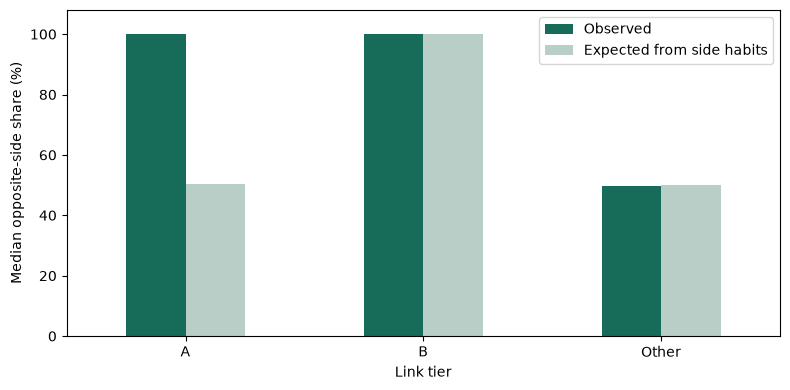

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

comparison = summary[["median_opposite_rate", "median_expected_opposite"]].mul(100)
comparison.columns = ["Observed", "Expected from side habits"]
ax = comparison.plot.bar(color=["#176c59", "#b9cec7"], rot=0, figsize=(8, 4))
ax.set(xlabel="Link tier", ylabel="Median opposite-side share (%)", ylim=(0, 108))
ax.get_figure().tight_layout()
plt.show()
con.close()

The result is a set of groups with patterns worth investigating. A connected group means there is a path of retained links between its accounts. It does not establish who controlled the accounts or whether the wagers were automated.

This reconstruction uses an explicit table key, excludes ambiguous account-round duplicates, and averages the timing control in both directions. The earlier historical audit used a different implementation, so its counts are reported separately in the README.